# Classification of Sterk elliptic subdiagrams

In [1]:
from IPython.display import Math
import numpy as np
import pandas as pd
from IPython.display import HTML
from collections import Counter
from collections import Counter

H = Lattices(ZZ)("H")
E8 = Lattices(ZZ)("E8")
E82 = E8.twist(2)
H2 = H.twist(2)

## Ambient Lattices and Coxeter Diagrams

In [2]:
# Coxeter diagrams of families of roots, built by the owned construction CoxeterDiagrams().from_roots

def Coxeter_Diagram(roots, labels=None, pos=None):
    """The rooted Coxeter diagram of a family of roots of L_20_2_0 ⊗ Q; vertex i is roots[i]."""
    return CoxeterDiagrams().from_roots(list(roots), positions=pos)

def plot_coxeter_diagram(G, v_labels, pos={}):
    vlabs = {v: k for v, k in enumerate(v_labels)}
    if pos == {}:
        display(G.plot(edge_labels=True, vertex_labels=vlabs, vertex_size=200))
    else:
        display(G.plot(edge_labels=True, vertex_labels=vlabs, vertex_size=200, pos=pos))

def root_intersection_matrix(vectors, labels, bil_form, show_table=False):
    M = matrix([[bil_form(x, y) for y in vectors] for x in vectors])
    n = len(vectors)

    if show_table:
        print("Diagonal entries/square norms: ")
        display([M[i, i] for i in range(n)])
        df = pd.DataFrame([[M[i, j] for j in range(n)] for i in range(n)], columns=list(labels), index=list(labels))
        display(HTML(df.to_html()))

    # Must be symmetric
    assert M == M.transpose()

    # Must have -2 or -4 on the diagonal
    assert {M[i, i] for i in range(n)} <= {-2, -4}

    # Diagonals should be square norms of vectors
    for i in range(n):
        assert M[i, i] == bil_form(vectors[i], vectors[i])

    return M

def roots_from_subgraph(H):
    return [V[index] for index in H.vertices()]

In [3]:
positions = {
    "Sterk_1": {
        0: [0, 0],
        1: [4, 0],
        2: [8, 0],
        3: [8, -4],
        4: [8, -8],
        5: [4, -8],
        6: [0, -8],
        7: [0, -4],
        8: [2, -6],
        9: [3.25, -4.75],
        10: [4.5, -3.5],
        11: [6, -2]
    },
    "Sterk_2": {
        0: [0, 0],
        1: [-4, 0],
        2: [-8, 0],
        3: [-7, 4],
        4: [-6, 8],
        5: [-5, 12],
        6: [-4, 16],
        7: [-3, 20],
        8: [-2, 24],
        9: [-2, 6]
    },
    "Sterk_3": {
        0: [0, -4],
        1: [0, 4],
        2: [0, 8],
        3: [0, 12],
        4: [0, 16],
        5: [4, 16],
        6: [8, 16],
        7: [12, 16],
        8: [20, 16],
        9: [4, 12],
        10: [6, 2],
        11: [14, 10]
    },
    "Sterk_4": {
        0: [0, 0],
        1: [0, 4],
        2: [0, 8],
        3: [4, 8],
        4: [8, 8],
        5: [12, 8],
        6: [16, 8],
        7: [16, 4],
        8: [16, 0],
        9: [4, 4],
        10: [12, 4]    
    },
    "Sterk_5": {
        0: [0, 0],
        1: [10, 0],
        2: [20, 0],
        3: [20, -10],
        4: [20, -20],
        5: [10, -20],
        6: [0, -20],
        7: [0, -10],
        8: [4, -4],
        9: [16, -4],
        10: [16, -16],
        11: [4, -16],
        12: [8, -8],
        13: [8, -12]
    }
}

Sterk_roots = {
    "Sterk_1": [],
    "Sterk_2": [],
    "Sterk_3": [],
    "Sterk_4": [],
    "Sterk_5": []
}

In [4]:
# Build (20, 2, 0) = U+U(2)+E_8+E_8, which contains (18, 2, 0) = U + E_8 + E_8 for the square Coxeter diagram

L_20_2_0 = H + H2 + E8 + E8

# Roots, dual vectors and their combinations live in the rational base change L ⊗ Q.
L_20_2_0_QQ = L_20_2_0.base_change(QQ)

dot = lambda x, y: L_20_2_0_QQ.b(x, y)
nm = lambda x: dot(x, x)

Gram_L_20_2_0 = L_20_2_0.gram_matrix()

e,f ,ep,fp, a1,a2,a3,a4,a5,a6,a7,a8, a1t,a2t,a3t,a4t,a5t,a6t,a7t,a8t = [L_20_2_0_QQ(x) for x in L_20_2_0.module_generators()]
eb,fb, epb,fpb, w1,w2,w3,w4,w5,w6,w7,w8, w1t,w2t,w3t,w4t,w5t,w6t,w7t,w8t = [L_20_2_0_QQ(x) for x in L_20_2_0.dual_basis()]

# The primes are the image of the diagonal embedding from E_8(2)
a1p = a1 + a1t
a2p = a2 + a2t
a3p = a3 + a3t
a4p = a4 + a4t 
a5p = a5 + a5t
a6p = a6 + a6t
a7p = a7 + a7t
a8p = a8 + a8t

w1p = w1 + w1t
w2p = w2 + w2t
w3p = w3 + w3t
w4p = w4 + w4t
w5p = w5 + w5t
w6p = w6 + w6t
w7p = w7 + w7t
w8p = w8 + w8t

MS      = [e,f,   ep,fp,   a1,a2,a3,a4,a5,a6,a7,a8, a1t,a2t,a3t,a4t,a5t,a6t,a7t,a8t]
MS_dual = [eb,fb, epb,fpb, w1,w2,w3,w4,w5,w6,w7,w8, w1t,w2t,w3t,w4t,w5t,w6t,w7t,w8t]

VS      = [ep,fp,   a1,a2,a3,a4,a5,a6,a7,a8, a1t,a2t,a3t,a4t,a5t,a6t,a7t,a8t]
VS_dual = [epb,fpb, w1,w2,w3,w4,w5,w6,w7,w8, w1t,w2t,w3t,w4t,w5t,w6t,w7t,w8t]

WS      = [e,f,   a1,a2,a3,a4,a5,a6,a7,a8, a1t,a2t,a3t,a4t,a5t,a6t,a7t,a8t]
WS_dual = [eb,fb, w1,w2,w3,w4,w5,w6,w7,w8, w1t,w2t,w3t,w4t,w5t,w6t,w7t,w8t]


AttributeError: 'OwnedJoinCategory.parent_class' object has no attribute 'codomain'

In [5]:
# Root vectors for (18, 2, 0), roots taken from above, v_i are according to numerical labeling above

v1 = a8t
v2 = ep + fp + w1 + w8t
v3 = a1 
v4 = a3
v5 = a4
v6 = a5
v7 = a6
v8 = a7
v9 = a8
v10 = ep + fp + w8 + w1t
v11 = a1t
v12 = a3t
v13 = a4t
v14 = a5t
v15 = a6t
v16 = a7t

v17 = ep + w8t
v18 = a2
v19 = ep + w8
v20 = a2t

v21 = fp - ep
v22 = 5 ep + 3 fp + 2 w2 + 2 w2t

roots_18_2_0 = [v1, v2, v3, v4, v5, v6, v7, v8, v9, v10, v11, v12, v13, v14, v15, v16, v17, v18, v19, v20, v21, v22]
labels = [f"$v_{ {r + 1} }$" for r in range( len( roots_18_2_0 ) )]
intersection_matrix_roots_18_2_0 = root_intersection_matrix(roots_18_2_0, labels = labels, bil_form=dot)

G_18_2_0 = Coxeter_Diagram(roots_18_2_0)
plot_coxeter_diagram(
    G_18_2_0, 
    v_labels = labels,
    pos = {
        0: [0, 0],
        1: [4, 0],
        2: [8, 0],
        3: [12, 0],
        4: [16, 0],
        5: [16, -4],
        6: [16, -8],
        7: [16, -12],
        8: [16, -16],
        9: [12, -16],
        10: [8, -16],
        11: [4, -16],
        12: [0, -16],
        13: [0, -12],
        14: [0, -8],
        15: [0, -4],
        16: [4, -4],
        17: [12, -4],
        18: [12, -12],
        19: [4, -12],
        20: [8, -10],
        21: [8, -6],
    }
)

NameError: name 'a8t' is not defined

In [6]:
# Root vectors for (18, 0, 0), roots taken from above, w_i are according to numerical labeling above

w1 = a1
w2 = a3
w3 = a4
w4 = a5
w5 = a6
w6 = a7
w7 = a8
w8 = w8 + e
w9 = f- e
w10 = w8t + e
w11 = a8t
w12 = a7t
w13 = a6t
w14 = a5t
w15 = a4t
w16 = a3t
w17 = a1t
w18 = a2
w19 = a2t

roots_18_0_0 = [w1, w2, w3, w4, w5, w6, w7, w8, w9, w10, w11, w12, w13, w14, w15, w16, w17, w18, w19]
intersection_matrix_roots_18_0_0 = root_intersection_matrix(
    roots_18_0_0, 
    labels = [f"$w_{ {r + 1} }$" for r in range( len(roots_18_0_0) )], 
    bil_form=dot
)

G_18_0_0 = Coxeter_Diagram(roots_18_0_0)
plot_coxeter_diagram(
    G_18_0_0, 
    v_labels = [f"$w_{ {i + 1} }$" for i in range( 19 )],
    pos = {
        0: [-4, 0],
        1: [-8, 0],
        2: [-12, 0],
        3: [-10, 4],
        4: [-8, 8],
        5: [-6, 12],
        6: [-4, 16],
        7: [-2, 20],
        8: [0, 24],
        9: [2, 20],
        10: [4, 16],
        11: [6, 12],
        12: [8, 8],
        13: [10, 4],
        14: [12, 0],
        15: [8, 0],
        16: [4, 0],
        17: [-4, 4],
        18: [4, 4]
    }
)

NameError: name 'a1' is not defined

## Functions

In [7]:
# Rooted Coxeter diagrams of the elliptic types, and the negative definite Gram matrices of their roots

def rooted_type(cartan_type, scale=None):
    return CoxeterDiagrams().from_cartan_type(cartan_type, rooted=True, scale=scale)

def type_matrix(diagram):
    return diagram.root_realization().gram_matrix()

# Type A

def graph_A_n(n):
    return rooted_type(["A", n])

def matrix_A_n(n):
    return Lattices(ZZ)(f"A{n}").gram_matrix()
    
def graph_A_n_2(n):
    return rooted_type(["A", n], scale=2)

def matrix_A_n_2(n):
    return Lattices(ZZ)(f"A{n}").twist(2).gram_matrix()

# Type B: n-1 roots of square -4 in a chain, the last of square -2

def graph_B_n_2(n):
    return rooted_type(["B", n], scale=2)

def matrix_B_n_2(n):
    return type_matrix( graph_B_n_2(n) )

# Type C: n-1 roots of square -2 in a chain, the last of square -4

def graph_C_n_2(n):
    return rooted_type(["C", n], scale=2)

def matrix_C_n_2(n):
    return type_matrix( graph_C_n_2(n) )

# Type D

def graph_D_n(n):
    return rooted_type(["D", n])

def matrix_D_n(n):
    return Lattices(ZZ)(f"D{n}").gram_matrix()
    
def graph_D_n_2(n):
    return rooted_type(["D", n], scale=2)
    
def matrix_D_n_2(n):
    return Lattices(ZZ)(f"D{n}").twist(2).gram_matrix()

# Type E6

def graph_E_6():
    return rooted_type(["E", 6])

def matrix_E_6():
    return Lattices(ZZ)("E6").gram_matrix()
    
def graph_E_6_2():
    return rooted_type(["E", 6], scale=2)

def matrix_E_6_2():
    return Lattices(ZZ)("E6").twist(2).gram_matrix()

# Type E7

def graph_E_7():
    return rooted_type(["E", 7])

def matrix_E_7():
    return Lattices(ZZ)("E7").gram_matrix()
    
def graph_E_7_2():
    return rooted_type(["E", 7], scale=2)

def matrix_E_7_2():
    return Lattices(ZZ)("E7").twist(2).gram_matrix()

# Type E8

def graph_E_8():
    return rooted_type(["E", 8])

def matrix_E_8():
    return Lattices(ZZ)("E8").gram_matrix()
    
def graph_E_8_2():
    return rooted_type(["E", 8], scale=2)

def matrix_E_8_2():
    return Lattices(ZZ)("E8").twist(2).gram_matrix()

# Type G2: a root of square -2 and a root of square -4 meeting with pairing 2

def graph_G_2():
    return rooted_type(["G", 2])
    
def matrix_G_2():
    return type_matrix(graph_G_2())

def get_all_rank_n_types(n):
    if n == 0:
        return [ 
            ("A_{0}" , NamedLattices.Zero.gram_matrix() ) 
       ]
    if n == 1:
        return [ 
            (f"A_{n}" ,matrix_A_n(1) ),
            (f"A_{n}(2)" ,matrix_A_n_2(1)) 
        ]
    if n == 2:
        return [ 
            (f"A_{n}",    matrix_A_n(2)),
            (f"A_{n}(2)", matrix_A_n_2(2)), 
            (f"G_{2}",    matrix_G_2()) 
        ]
    if n == 3:
        return [ 
            (f"A_{n}",    matrix_A_n(3)),
            (f"A_{n}(2)", matrix_A_n_2(3)), 
            (f"B_{n}(2)", matrix_B_n_2(3)),
            (f"C_{n}(2)", matrix_C_n_2(3))
        ]
    else:
        Ms = [ 
            (f"A_{n}",    matrix_A_n(n)),
            (f"A_{n}(2)", matrix_A_n_2(n)), 
            (f"B_{n}(2)", matrix_B_n_2(n)),
            (f"C_{n}(2)", matrix_C_n_2(n)),
            (f"D_{n}",    matrix_D_n(n)),
            (f"D_{n}(2)", matrix_D_n_2(n)) 
        ]
        if n == 6:
            Ms.extend([
                (f"E_6",    matrix_E_6() ),
                (f"E_6(2)", matrix_E_6_2() )
            ])
        elif n == 7:
            Ms.extend([
                (f"E_7",    matrix_E_7() ),
                (f"E_7(2)", matrix_E_7_2() )
            ])
        elif n == 8:
            Ms.extend([
                (f"E_8", matrix_E_8() ),
                (f"E_8(2)", matrix_E_8_2() )
            ])
        return Ms

type_A_graphs = [ graph_A_n_2(n) for n in range(11) ]
type_B_graphs = [ graph_B_n_2(n) for n in range(11) if n > 2]
type_C_graphs = [ graph_C_n_2(n) for n in range(11) if n > 2]
type_D_graphs = [ graph_D_n_2(n) for n in range(11) if n > 3]
type_E_graphs = [ graph_E_6_2(), graph_E_7_2(), graph_E_8_2() ]

type_A_matrices = [ matrix_A_n_2(n) for n in range(11) ]
type_B_matrices = [ matrix_B_n_2(n) for n in range(11) if n > 2 ]
type_C_matrices = [ matrix_C_n_2(n) for n in range(11) if n > 2]
type_D_matrices = [ matrix_D_n_2(n) for n in range(11) if n > 3]
type_E_matrices = [ matrix_E_6_2(), matrix_E_7_2(), matrix_E_8_2() ]

get_all_rank_n_types(3)

AssertionError: cannot form a Coxeter diagram from roots: no roots were given, and the diagram needs at least one to determine its lattice

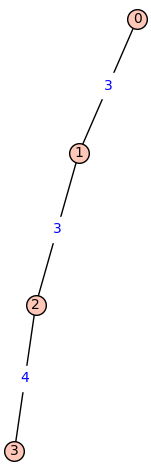

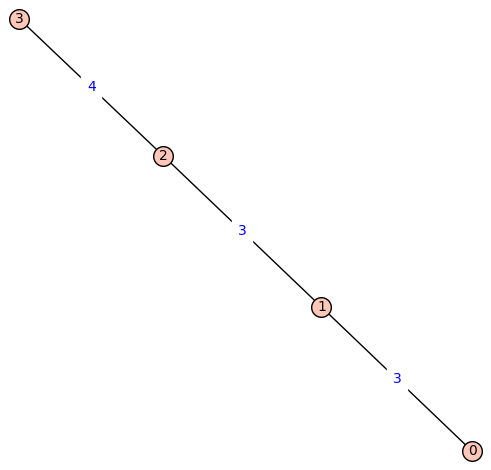

In [8]:
show( graph_B_n_2(4).plot(edge_labels=True) )
show( graph_C_n_2(4).plot(edge_labels=True) )

In [9]:
def sterk_subgraph_to_matrix(H, sterktype):
    roots = Sterk_roots[sterktype]
    H_roots = [ roots[index] for index in H.vertices() ]
    return root_intersection_matrix(
        H_roots, 
        labels = H.vertices(), 
        bil_form=dot
    )

def sterk_is_elliptic_subgraph(H, sterktype):
    return H.is_elliptic()

In [10]:
def is_elliptic_subgraph(H):
    return H.is_elliptic()

def is_parabolic_subgraph(H, G):
    pass

def is_maximal_elliptic_subgraph(H, G):
    pass

def is_maximal_parabolic_subgraph(H, G):
    pass

def plot_sterk_subgraph(H, sterktype):
    assert sterktype in ["Sterk_1", "Sterk_2", "Sterk_3", "Sterk_3", "Sterk_4", "Sterk_5"]
    display(get_plot_sterk_subgraph(H, sterktype))

def get_plot_sterk_subgraph(H, sterktype):
    assert sterktype in ["Sterk_1", "Sterk_2", "Sterk_3", "Sterk_3", "Sterk_4", "Sterk_5"]
    G = Sterk_quivers[sterktype]
    red_edges = [ e for e in G.edges() if e in H.edges() ]
    red_vertices = [ e for e in G.vertices() if e in H.vertices() ]
    return G.plot(
        vertex_size=150,
        edge_colors={'red': red_edges},
        vertex_color='lightcyan',
        vertex_colors={'red': red_vertices},
        pos= positions[sterktype]
    )

def get_coxeter_label(H, sterktype):
    return H.scaled_cartan_type()

def summarize_elliptic_subgraphs(subgraphs, sterktype):
    show(f"Total number of elliptic subdiagrams: {len(subgraphs) }")
    show("---------------------------------")
    
    ranks = [H.num_vertices() for H in subgraphs]
    d = Counter( ranks )
    n = Sterk_quivers[sterktype].num_vertices()
    for i in reversed(range(n+1)):
        show(f"Number of rank {i} elliptic subdiagrams: {d[i]}")
        rank_i_types = [get_coxeter_label(H, sterktype) for H in subgraphs if H.num_vertices() == i]
        di = Counter(rank_i_types)
        for k in di.keys():
            print("  ", k, ": ", di[k])
    
    show("---------------------------------")
    show("Counts of subdiagrams by type:")
    all_types = [get_coxeter_label(H, sterktype) for H in subgraphs]
    dp = Counter(all_types)
    for k in dp.keys():
        show(k, ": ", dp[k])

def display_elliptic_subgraphs(subgraphs, sterktype, save=False):
    n = Sterk_quivers[sterktype].num_vertices()
    j = 0
    for i in reversed(range(n+1)):
        rank_i_subgraphs = [H for H in subgraphs if H.num_vertices() == i]
        show(f"Rank {i}: ")
        for H in rank_i_subgraphs:
            plot_sterk_subgraph( H, sterktype )
            this_type = get_coxeter_label(H, sterktype)
            show(this_type)
            if save:
                p = get_plot_sterk_subgraph(H, sterktype)
                p.save(f"/home/zack/{sterktype}/elliptic_subdiagram_number_{j}_rank_{i}_type_{this_type}_index_{j}.png")
            j = j+1
        show("--------------------------------------")



## Sterk 1

In [11]:
# Sterk 1

s1_1 = v3 + v11
s1_2 = v4 + v12
s1_3 = v5 + v13
s1_4 = v6 + v14
s1_5 = v7 + v15
s1_6 = v8 + v16
s1_7 = v9 + v1
s1_8 = v10 + v2
s1_9 = v17 + v19
s1_10 = v21
s1_11 = v22
s1_12 = v18 + v20

Sterk_roots["Sterk_1"] = [s1_1, s1_2, s1_3, s1_4, s1_5, s1_6, s1_7, s1_8, s1_9, s1_10, s1_11, s1_12]
Sterk1_labels = range( len(Sterk_roots["Sterk_1"]) )

Sterk1_gram_matrix = root_intersection_matrix(
    Sterk_roots["Sterk_1"], 
    labels = Sterk1_labels, 
    bil_form=dot
)

# positions = {
#     "Sterk_1": {
#         0: [0, 0],
#         1: [4, 0],
#         2: [8, 0],
#         3: [8, -4],
#         4: [8, -8],
#         5: [4, -8],
#         6: [0, -8],
#         7: [0, -4],
#         8: [0, -8],
#         9: [2, -6],
#         10: [4, -4],
#         11: [6, -2]
#     }


Sterk1_Coxeter_diagram = Coxeter_Diagram(Sterk_roots["Sterk_1"])
plot_coxeter_diagram(
    Sterk1_Coxeter_diagram, 
    v_labels = Sterk1_labels,
    pos = positions["Sterk_1"]
)

NameError: name 'v3' is not defined

In [12]:
Sterk_quivers = {
    "Sterk_1": Sterk1_Coxeter_diagram
}

Sterk_quivers["Sterk_1"].plot(edge_labels=True)

NameError: name 'Sterk1_Coxeter_diagram' is not defined

In [13]:
def get_connected_elliptic_subgraphs(G, sterktype):
    connected_elliptic_subgraphs_by_rank = list(reversed(sorted(
        [H for H in G.elliptic_subdiagrams() if H.is_connected() and H.num_vertices() > 0],
        key=lambda H: H.num_vertices()
    )))

    return connected_elliptic_subgraphs_by_rank

Sterk1_connected_elliptic_subgraphs = get_connected_elliptic_subgraphs(
    Sterk_quivers["Sterk_1"], "Sterk_1"
)
show("Done")

NameError: name 'Sterk_quivers' is not defined

In [14]:
summarize_elliptic_subgraphs(Sterk1_connected_elliptic_subgraphs, "Sterk_1")

NameError: name 'Sterk1_connected_elliptic_subgraphs' is not defined

In [15]:
# display_elliptic_subgraphs(Sterk1_connected_elliptic_subgraphs, "Sterk_1", save=True)

## Sterk 2

In [16]:
# Sterk 2

s2_1 = w1 + w17
s2_2 = w2 + w16
s2_3 = w3 + w15
s2_4 = w4 + w14
s2_5 = w5 + w13
s2_6 = w6 + w12
s2_7 = w7 + w11
s2_8 = w8 + w10
s2_9 = w9
s2_10 = w18 + w19

Sterk_roots["Sterk_2"] = [s2_1, s2_2, s2_3, s2_4, s2_5, s2_6, s2_7, s2_8, s2_9, s2_10]
Sterk2_labels = range( len(Sterk_roots["Sterk_2"]) )

Sterk2_gram_matrix = root_intersection_matrix(
    Sterk_roots["Sterk_2"], 
    labels = Sterk2_labels, 
    bil_form=dot 
)

Sterk2_Coxeter_diagram = Coxeter_Diagram(Sterk_roots["Sterk_2"])


plot_coxeter_diagram(
    Sterk2_Coxeter_diagram, 
    v_labels = Sterk2_labels,
    pos = positions["Sterk_2"]
)

NameError: name 'w1' is not defined

In [17]:
Sterk_quivers = {
    "Sterk_1": Sterk1_Coxeter_diagram,
    "Sterk_2": Sterk2_Coxeter_diagram,
}

Sterk_quivers["Sterk_2"].plot(edge_labels=True)

NameError: name 'Sterk1_Coxeter_diagram' is not defined

In [18]:
Sterk2_connected_elliptic_subgraphs = get_connected_elliptic_subgraphs(
    Sterk_quivers["Sterk_2"], "Sterk_2"
)
show("Done")

NameError: name 'Sterk_quivers' is not defined

In [19]:
summarize_elliptic_subgraphs(Sterk2_connected_elliptic_subgraphs, "Sterk_2")

NameError: name 'Sterk2_connected_elliptic_subgraphs' is not defined

In [20]:
# display_elliptic_subgraphs(Sterk2_connected_elliptic_subgraphs, "Sterk_2", save=True)

## Sterk 3

In [21]:
# Sterk 3

wa = lambda x: x + (1/2)*dot(v22, x) * v22
I = lambda x: x + wa(x)

s3_1 = v13
s3_2 = v14 + v12
s3_3 = v15 + v11
s3_4 = v16 + v10
s3_5 = v1 + v9
s3_6 = v2 + v8
s3_7 = v3 + v7
s3_8 = v4 + v6
s3_9 = v5
s3_10 = v17 + v19
s3_11 = I(v20) #v22 + 2*v20
s3_12 = I(v18) #v22 + 2*v18

Sterk_roots["Sterk_3"] = [s3_1, s3_2, s3_3, s3_4, s3_5, s3_6, s3_7, s3_8, s3_9, s3_10, s3_11, s3_12]
Sterk3_labels = range( len(Sterk_roots["Sterk_3"]) )
Sterk3_gram_matrix = root_intersection_matrix(
    Sterk_roots["Sterk_3"], 
    labels = Sterk3_labels, 
    bil_form=dot
)

Sterk3_Coxeter_diagram = Coxeter_Diagram(Sterk_roots["Sterk_3"])
plot_coxeter_diagram(
    Sterk3_Coxeter_diagram, 
    v_labels = Sterk3_labels,
    pos = positions["Sterk_3"]
)

NameError: name 'v13' is not defined

In [22]:
Sterk_quivers = {
    "Sterk_1": Sterk1_Coxeter_diagram,
    "Sterk_2": Sterk2_Coxeter_diagram,
    "Sterk_3": Sterk3_Coxeter_diagram,
}

Sterk_quivers["Sterk_3"].plot(edge_labels=True)

NameError: name 'Sterk1_Coxeter_diagram' is not defined

In [23]:
Sterk3_connected_elliptic_subgraphs = get_connected_elliptic_subgraphs(
    Sterk_quivers["Sterk_3"], "Sterk_3"
)
show("Done")

NameError: name 'Sterk_quivers' is not defined

In [24]:
summarize_elliptic_subgraphs(Sterk3_connected_elliptic_subgraphs, "Sterk_3")

NameError: name 'Sterk3_connected_elliptic_subgraphs' is not defined

In [25]:
display_elliptic_subgraphs(Sterk3_connected_elliptic_subgraphs, "Sterk_3", save=True)

NameError: name 'Sterk3_connected_elliptic_subgraphs' is not defined

## Sterk 4

In [26]:
s4_1 = v15
s4_2 = v16 + v14
s4_3 = v1 + v13
s4_4 = v2 + v12
s4_5 = v3 + v11
s4_6 = v4 + v10
s4_7 = v5 + v9
s4_8 = v6 + v8
s4_9 = v7
s4_10 = v17 + v20
s4_11 = v18 + v19
s4_12 = v22 + v21

Sterk_roots["Sterk_4"] = [s4_1, s4_2, s4_3, s4_4, s4_5, s4_6, s4_7, s4_8, s4_9, s4_10, s4_11]

Sterk4_labels = range( len(Sterk_roots["Sterk_4"]) )


Sterk4_gram_matrix = root_intersection_matrix(
    Sterk_roots["Sterk_4"], 
    labels = Sterk2_labels, 
    bil_form=dot
)

Sterk4_Coxeter_diagram = Coxeter_Diagram(Sterk_roots["Sterk_4"])

plot_coxeter_diagram(
    Sterk4_Coxeter_diagram, 
    v_labels = Sterk4_labels,
    pos = positions["Sterk_4"] 
)

NameError: name 'v15' is not defined

In [27]:
Sterk_quivers = {
    "Sterk_1": Sterk1_Coxeter_diagram,
    "Sterk_2": Sterk2_Coxeter_diagram,
    "Sterk_3": Sterk3_Coxeter_diagram,
    "Sterk_4": Sterk4_Coxeter_diagram,
}

Sterk_quivers["Sterk_4"].plot(edge_labels=True)

NameError: name 'Sterk1_Coxeter_diagram' is not defined

In [28]:
Sterk4_connected_elliptic_subgraphs = get_connected_elliptic_subgraphs(
    Sterk_quivers["Sterk_4"], "Sterk_4"
)
show("Done")

NameError: name 'Sterk_quivers' is not defined

In [29]:
summarize_elliptic_subgraphs(Sterk4_connected_elliptic_subgraphs, "Sterk_4")

NameError: name 'Sterk4_connected_elliptic_subgraphs' is not defined

In [30]:
display_elliptic_subgraphs(Sterk4_connected_elliptic_subgraphs, "Sterk_4", save=True)

NameError: name 'Sterk4_connected_elliptic_subgraphs' is not defined

## Sterk 5

In [31]:
# Sterk 5

s5_1 = v16 + 2v1 + v2
s5_2 = v2 + 2v3 + v4
s5_3 = v4 + 2v5 + v6
s5_4 = v6 + 2v7 + v8
s5_5 = v8 + 2v9 + v10
s5_6 = v10 + 2v11 + v12
s5_7 = v12 + 2v13 + v14
s5_8 = v14 + 2v15 + v16
s5_9 = v17
s5_10 = v18
s5_11 = v19
s5_12 = v20
s5_13 = v21
s5_14 = v22

Sterk_roots["Sterk_5"] = [s5_1, s5_2, s5_3, s5_4, s5_5, s5_6, s5_7, s5_8, s5_9, s5_10, s5_11, s5_12, s5_13, s5_14]

Sterk5_labels = range( len(Sterk_roots["Sterk_5"]) )

Sterk5_gram_matrix = root_intersection_matrix(
    Sterk_roots["Sterk_5"], 
    labels = Sterk5_labels, 
    bil_form=dot
)

Sterk5_Coxeter_diagram = Coxeter_Diagram(Sterk_roots["Sterk_5"])

plot_coxeter_diagram(
    Sterk5_Coxeter_diagram, 
    v_labels = Sterk5_labels,
    pos = positions["Sterk_5"]
)

NameError: name 'v16' is not defined

In [32]:
Sterk_quivers = {
    "Sterk_1": Sterk1_Coxeter_diagram,
    "Sterk_2": Sterk2_Coxeter_diagram,
    "Sterk_3": Sterk3_Coxeter_diagram,
    "Sterk_4": Sterk4_Coxeter_diagram,
    "Sterk_5": Sterk5_Coxeter_diagram,
}

Sterk_quivers["Sterk_5"].plot(edge_labels=True)

NameError: name 'Sterk1_Coxeter_diagram' is not defined

In [33]:
Sterk5_connected_elliptic_subgraphs = get_connected_elliptic_subgraphs(
    Sterk_quivers["Sterk_5"], "Sterk_5"
)
show("Done")

NameError: name 'Sterk_quivers' is not defined

In [34]:
summarize_elliptic_subgraphs(Sterk5_connected_elliptic_subgraphs, "Sterk_5")

NameError: name 'Sterk5_connected_elliptic_subgraphs' is not defined

In [35]:
display_elliptic_subgraphs(Sterk5_connected_elliptic_subgraphs, "Sterk_5", save=True)

NameError: name 'Sterk5_connected_elliptic_subgraphs' is not defined

## Summary of Maximal Elliptic Diagrams

In [36]:
def maximal_elliptics(all_elliptics):
    maximals = []
    for H in all_elliptics:
        is_subset_status = [ 
            set( H.vertices() ).issubset( set( Hp.vertices() ) ) 
            for Hp in  
            [ s for s in all_elliptics if s != H ]
        ]
        H_is_a_subset_of_something = reduce(lambda x, y: x or y, is_subset_status)
        if H_is_a_subset_of_something:
            continue
        else:
            maximals.append(H)
    return maximals

def summarize_maximal_elliptics(all_elliptics, sterktype):
    maximals = [ (H, get_coxeter_label(H, sterktype )) for H in maximal_elliptics(all_elliptics) ]
    show(f"Number of maximal elliptics: { len(maximals)}" )
    
    maximals = list( sorted( maximals, key = lambda x: x[1] ) )
    
    for H, label in maximals:
        plot_sterk_subgraph(H, sterktype)
        show(label)

In [37]:
all_elliptics = {
    "Sterk_1": Sterk1_connected_elliptic_subgraphs,
    "Sterk_2": Sterk2_connected_elliptic_subgraphs,
    "Sterk_3": Sterk3_connected_elliptic_subgraphs,
    "Sterk_4": Sterk4_connected_elliptic_subgraphs,
    "Sterk_5": Sterk5_connected_elliptic_subgraphs,
}


lens = [ len(all_elliptics[k]) for k in all_elliptics] 
show(f"Number of (ALL) elliptics in Sterk 1 through 5: {lens}")
show(f"Total number of (ALL) elliptics in all Sterk diagrams: {sum(lens )}")

NameError: name 'Sterk1_connected_elliptic_subgraphs' is not defined

In [38]:
all_maximal_elliptics = {
    "Sterk_1": maximal_elliptics( Sterk1_connected_elliptic_subgraphs ),
    "Sterk_2": maximal_elliptics( Sterk2_connected_elliptic_subgraphs ),
    "Sterk_3": maximal_elliptics( Sterk3_connected_elliptic_subgraphs ),
    "Sterk_4": maximal_elliptics( Sterk4_connected_elliptic_subgraphs ),
    "Sterk_5": maximal_elliptics( Sterk5_connected_elliptic_subgraphs ),
}

lens = [ len(all_maximal_elliptics[k]) for k in all_maximal_elliptics] 
show(f"Number of MAXIMAL elliptics in Sterk 1 through 5: {lens}")
show(f"Total number of MAXIMAL elliptics in all Sterk diagrams: {sum(lens )}")

NameError: name 'Sterk1_connected_elliptic_subgraphs' is not defined

### Maximal elliptics in Sterk 1

In [39]:
summarize_maximal_elliptics(Sterk1_connected_elliptic_subgraphs, "Sterk_1")

NameError: name 'Sterk1_connected_elliptic_subgraphs' is not defined

### Maximal elliptics in Sterk 2

In [40]:
summarize_maximal_elliptics(Sterk2_connected_elliptic_subgraphs, "Sterk_2")

NameError: name 'Sterk2_connected_elliptic_subgraphs' is not defined

### Maximal elliptics in Sterk 3

In [41]:
summarize_maximal_elliptics(Sterk3_connected_elliptic_subgraphs, "Sterk_3")

NameError: name 'Sterk3_connected_elliptic_subgraphs' is not defined

### Maximal elliptics in Sterk 4

In [42]:
summarize_maximal_elliptics(Sterk4_connected_elliptic_subgraphs, "Sterk_4")

NameError: name 'Sterk4_connected_elliptic_subgraphs' is not defined

### Maximal elliptics in Sterk 5

In [43]:
summarize_maximal_elliptics(Sterk5_connected_elliptic_subgraphs, "Sterk_5")

NameError: name 'Sterk5_connected_elliptic_subgraphs' is not defined

## Orbits

In [44]:

def summarize_maximal_orbits(sterktype):
    G = Sterk_quivers[sterktype]
    AutG = G.Aut()
    maximals = all_maximal_elliptics[sterktype]
    orbits = set()

    for H in maximals:
        orb = AutG.orbit( frozenset(H.vertices()) )
        lp = sorted( [ tuple( sorted(l) ) for l in orb] )
        orbits.add(tuple( lp ))

    labeled_orbit_representatives = sorted([
        ( G.induced_subdiagram(H[0]), get_coxeter_label( G.induced_subdiagram(H[0]) , sterktype ) ) 
        for H in orbits 
    ], key=lambda x: str(x[1]) )
    
    show(f"Number of maximal orbits:{len(labeled_orbit_representatives)}")
    for o in labeled_orbit_representatives:
        H = o[0]
        label = o[1]
        plot_sterk_subgraph(H, sterktype)
        show(label, ": ", H.vertices())
        show("--------------------------")


summarize_maximal_orbits("Sterk_1")

NameError: name 'Sterk_quivers' is not defined

In [45]:
summarize_maximal_orbits("Sterk_2")

NameError: name 'Sterk_quivers' is not defined

In [46]:
summarize_maximal_orbits("Sterk_3")

NameError: name 'Sterk_quivers' is not defined

In [47]:
summarize_maximal_orbits("Sterk_4")

NameError: name 'Sterk_quivers' is not defined

In [48]:
summarize_maximal_orbits("Sterk_5")

NameError: name 'Sterk_quivers' is not defined

## Symmetric Maimal Elliptics Upstairs

In [49]:
G_18_0_0

NameError: name 'G_18_0_0' is not defined

In [50]:
Quiver_18_0_0 = G_18_0_0
Quiver_18_0_0.plot(edge_labels=True)

NameError: name 'G_18_0_0' is not defined

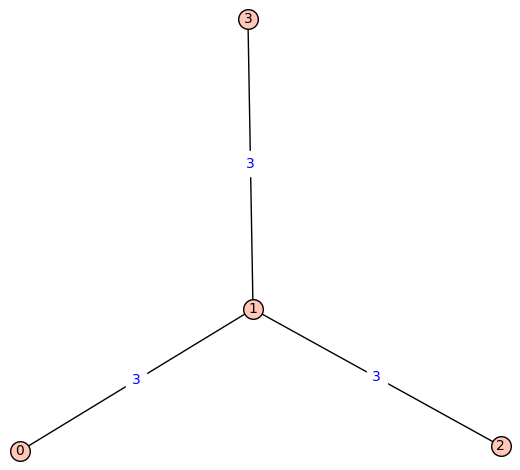

In [51]:
# test_G = Graph([ (1,1,-2), (1,2,1), (2,2,-2) ], loops=True)
test_G = graph_D_n(4)
test_G.plot(edge_labels=True) 

In [52]:
def is_elliptic_subgraph(H):
    return H.is_elliptic()
    
def get_all_elliptic_subgraphs(G):
    return list(reversed(sorted(
        [H for H in G.elliptic_subdiagrams() if H.num_vertices() > 0],
        key=lambda H: H.num_vertices()
    )))


get_all_elliptic_subgraphs(test_G)[0]

rooted Coxeter diagram on 4 vertices

In [53]:
def get_coxeter_label_graph(G):
    return G.scaled_cartan_type()

def get_all_orbits_elliptic_subgraphs(G):
    return [ orbit.representative() for orbit in G.elliptic_subdiagram_orbits() ]
    
def get_labeled_orbits(G):
    orbits = get_all_orbits_elliptic_subgraphs(G)
    labels = []
    for x in orbits:
        lsp = [ str(t) for t in x.component_scaled_cartan_types() ]
        label = reduce(lambda a,b: a + " ⊕ " + b, lsp)
        labels.append( (label, x) )
    return labels
    


In [54]:
all_elliptics_orbits = get_labeled_orbits(Quiver_18_0_0)

NameError: name 'Quiver_18_0_0' is not defined

In [55]:
len( all_elliptics_orbits )

NameError: name 'all_elliptics_orbits' is not defined